# Базовая модель (Logistic Regression)

Строим линейный бейзлайн для оценки вероятности дефолта и проверяем открытые вопросы, оставшиеся после разведочного анализа.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_curve,
    precision_recall_curve,
)

from src.data import load_raw, clean

## 1. Загрузка данных и разбиение

Загружаем очищенный датасет и фиксируем отложенную тестовую выборку со стратификацией по целевой переменной.

In [2]:
df = clean(load_raw())
print("Строк после очистки:", len(df))

Строк после очистки: 32398


In [3]:
X = df.drop(columns=["loan_status"])
y = df["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Train: {X_train.shape[0]} строк, доля дефолтов: {y_train.mean():.4f}")
print(f"Test:  {X_test.shape[0]} строк, доля дефолтов: {y_test.mean():.4f}")

Train: 25918 строк, доля дефолтов: 0.2188
Test:  6480 строк, доля дефолтов: 0.2188


## 2. Препроцессинг и пайплайн

Готовим признаки для линейной модели. Все статистики для заполнения пропусков и масштабирования считаем только на обучающей выборке.

In [4]:
NUM_COLS = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
]
CAT_COLS = ["person_home_ownership", "loan_intent"]
PASS_COLS = ["emp_length_missing", "loan_grade", "cb_person_default_on_file"]

GRADE_MAP = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4, "F": 5, "G": 6}
DEFAULT_MAP = {"N": 0, "Y": 1}

emp_median = X_train["person_emp_length"].median()
rate_medians = X_train.groupby("loan_grade")["loan_int_rate"].median()

In [5]:
def preprocess_df(data: pd.DataFrame) -> pd.DataFrame:
    """Заполняет пропуски статистиками train, кодирует порядковые признаки и логарифмирует доход и сумму."""
    d = data.copy()
    d["emp_length_missing"] = d["person_emp_length"].isna().astype(int)
    d["person_emp_length"] = d["person_emp_length"].fillna(emp_median)
    d["loan_int_rate"] = d["loan_int_rate"].fillna(d["loan_grade"].map(rate_medians))
    d["loan_grade"] = d["loan_grade"].map(GRADE_MAP)
    d["cb_person_default_on_file"] = d["cb_person_default_on_file"].map(DEFAULT_MAP)
    for col in ["person_income", "loan_amnt"]:
        d[col] = np.log1p(d[col])
    return d


X_train_prep = preprocess_df(X_train)
X_test_prep = preprocess_df(X_test)

In [6]:
def build_pipeline(drop_cols: list[str] | None = None) -> Pipeline:
    """Собирает пайплайн масштабирования, One-Hot кодирования и логистической регрессии."""
    drop_set = set(drop_cols or [])
    num_cols = [c for c in NUM_COLS if c not in drop_set]
    pass_cols = [c for c in PASS_COLS if c not in drop_set]

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CAT_COLS),
            ("pass", "passthrough", pass_cols),
        ],
        verbose_feature_names_out=False,
    )
    return Pipeline([
        ("prep", preprocessor),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
    ])

## 3. Обучение и проверка гипотез из EDA

Сравниваем базовую модель на всех признаках с вариантами без длины кредитной истории и без внутренних банковских оценок.

In [7]:
experiments = {
    "LogReg (все признаки)": [],
    "LogReg (без cb_person_cred_hist_length)": ["cb_person_cred_hist_length"],
    "LogReg (без loan_grade и loan_int_rate)": ["loan_grade", "loan_int_rate"],
}

fitted_models = {}
rows = []

for name, drop_cols in experiments.items():
    pipe = build_pipeline(drop_cols)
    X_tr = X_train_prep.drop(columns=drop_cols)
    X_te = X_test_prep.drop(columns=drop_cols)

    pipe.fit(X_tr, y_train)
    fitted_models[name] = pipe

    y_proba = pipe.predict_proba(X_te)[:, 1]
    y_pred = (y_proba >= 0.5).astype(int)

    rows.append({
        "Модель": name,
        "ROC-AUC": round(roc_auc_score(y_test, y_proba), 4),
        "PR-AUC": round(average_precision_score(y_test, y_proba), 4),
        "F1": round(f1_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
    })

results_df = pd.DataFrame(rows)
results_df

,Модель,ROC-AUC,PR-AUC,F1,Precision,Recall
0,LogReg (все признаки),0.8764,0.7095,0.6409,0.5366,0.7955
1,LogReg (без cb_person_cred_hist_length),0.8763,0.7095,0.6405,0.5364,0.7948
2,LogReg (без loan_grade и loan_int_rate),0.8198,0.6343,0.5611,0.4623,0.7137


## 4. Визуализация и интерпретация

Оцениваем кривые качества основной модели на тесте и смотрим, какие признаки сильнее всего смещают оценку риска.

In [8]:
best_pipe = fitted_models["LogReg (все признаки)"]
y_proba_best = best_pipe.predict_proba(X_test_prep)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_proba_best)
prec, rec, _ = precision_recall_curve(y_test, y_proba_best)
roc_auc_val = roc_auc_score(y_test, y_proba_best)
pr_auc_val = average_precision_score(y_test, y_proba_best)

feature_names = best_pipe.named_steps["prep"].get_feature_names_out()
coefs = best_pipe.named_steps["clf"].coef_[0]

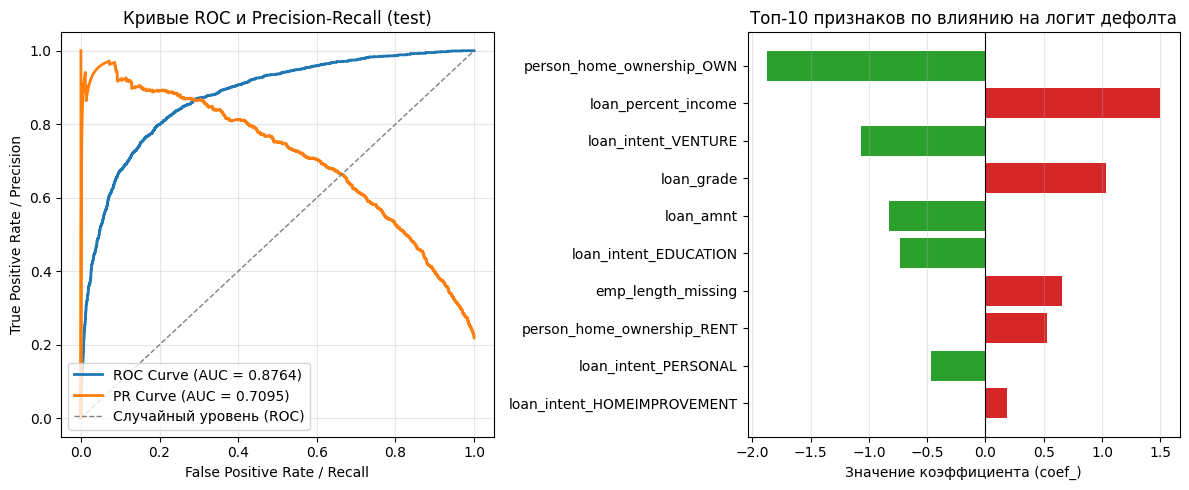

In [9]:
feature_names = best_pipe.named_steps["prep"].get_feature_names_out()
coefs = best_pipe.named_steps["clf"].coef_[0]

coef_df = (
    pd.DataFrame({"feature": feature_names, "coef": coefs, "abs_coef": np.abs(coefs)})
    .sort_values("abs_coef", ascending=False)
    .head(10)
    .sort_values("abs_coef", ascending=True)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc_val:.4f})", color="#1f77b4", lw=2)
axes[0].plot(rec, prec, label=f"PR Curve (AUC = {pr_auc_val:.4f})", color="#ff7f0e", lw=2)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", lw=1, label="Случайный уровень (ROC)")
axes[0].set_xlabel("False Positive Rate / Recall")
axes[0].set_ylabel("True Positive Rate / Precision")
axes[0].set_title("Кривые ROC и Precision-Recall (test)")
axes[0].legend(loc="lower left")
axes[0].grid(alpha=0.3)

colors = ["#d62728" if c > 0 else "#2ca02c" for c in coef_df["coef"]]
axes[1].barh(coef_df["feature"], coef_df["coef"], color=colors)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Значение коэффициента (coef_)")
axes[1].set_title("Топ-10 признаков по влиянию на логит дефолта")
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Выводы

- Линейный baseline задаёт ориентир качества на тесте: `ROC-AUC = 0.8764`, `PR-AUC = 0.7095`.
- Удаление `cb_person_cred_hist_length` не меняет метрики, поэтому признак оставляем — регуляризация справляется с его корреляцией с возрастом.
- Без `loan_grade` и `loan_int_rate` качество проседает сильнее всего (`ROC-AUC` падает до `0.8198`), а сам `loan_grade` входит в число главных факторов риска, поэтому оба признака сохраняем в модели.